# ILP -> Platform Schedule conversion test

This notebook tests conversion of ILP outputs (`variables_a/z/x`, `stream_dict`) into the platform `Schedule` object.

Notes:
- Time conversion is controlled by `time_scale_to_ns`.
- For rctsn outputs in microseconds, use `time_scale_to_ns = 1000` to map into platform nanosecond fields.

In [21]:
%matplotlib inline

from pathlib import Path
from collections import Counter
import json

from ilp_to_platform import (
    load_ilp_artifacts,
    convert_ilp_artifacts_to_schedule,
    summarize_conversion,
)


In [31]:
RUN_DIR = Path("rctsn/data/output/run_20260314_163748_02939ae4")

# Platform uses *_ns fields in schedule objects, so we scale ILP us->ns by default.
time_scale_to_ns = 1000

artifacts = load_ilp_artifacts(RUN_DIR)
result = convert_ilp_artifacts_to_schedule(
    artifacts,
    time_scale_to_ns=time_scale_to_ns,
    duration_mode="robust",
    compact_periodic=False,  # exact per repetition slots
)

summary = summarize_conversion(result)
summary

{'n_slots': 1701,
 'n_active_streams': 143,
 'n_selected_paths': 143,
 'n_ports_used': 30,
 'cycle_ns': 8000000,
 'dropped_entries': 0,
 'wrapped_entries': 0}

In [32]:
print("Cycle (ns):", result.cycle_ns)
print("Active streams:", len(result.active_streams))
print("Selected paths:", len(result.selected_paths))
print("Slots:", len(result.schedule))
print("Ports used:", len(result.port_tuple_to_port_id))
print("Dropped x-entries:", result.dropped_entries)
print("Wrapped entries:", result.wrapped_entries)

print("\nSample selected paths:")
for s in sorted(list(result.selected_paths.keys()))[:10]:
    print(f"stream {s} -> path {result.selected_paths[s]}")

print("\nSample port mapping:")
for p, pid in list(result.port_tuple_to_port_id.items())[:10]:
    print(pid, p)

Cycle (ns): 8000000
Active streams: 143
Selected paths: 143
Slots: 1701
Ports used: 30
Dropped x-entries: 0
Wrapped entries: 0

Sample selected paths:
stream 0 -> path 0
stream 1 -> path 0
stream 2 -> path 0
stream 3 -> path 0
stream 4 -> path 0
stream 5 -> path 0
stream 6 -> path 0
stream 7 -> path 0
stream 8 -> path 0
stream 9 -> path 0

Sample port mapping:
1 ('0-ED1', '0-SW1')
2 ('0-ED10', '0-SW4')
3 ('0-ED11', '0-SW4')
4 ('0-ED12', '0-SW4')
5 ('0-ED2', '0-SW1')
6 ('0-ED3', '0-SW1')
7 ('0-ED4', '0-SW2')
8 ('0-ED5', '0-SW2')
9 ('0-ED6', '0-SW2')
10 ('0-ED7', '0-SW3')


In [33]:
conflicts = result.schedule.validate_conflicts()
print("Conflicts:", len(conflicts))
if conflicts:
    print("First 5 conflicts:")
    for c1, c2 in conflicts[:5]:
        print(
            f"port={c1.port_id} s{c1.stream_id} [{c1.start_ns},{c1.end_ns}]",
            "<->",
            f"s{c2.stream_id} [{c2.start_ns},{c2.end_ns}]",
        )

Conflicts: 0


Top ports: [22, 21, 26, 17, 30, 16, 18, 7, 27, 10]


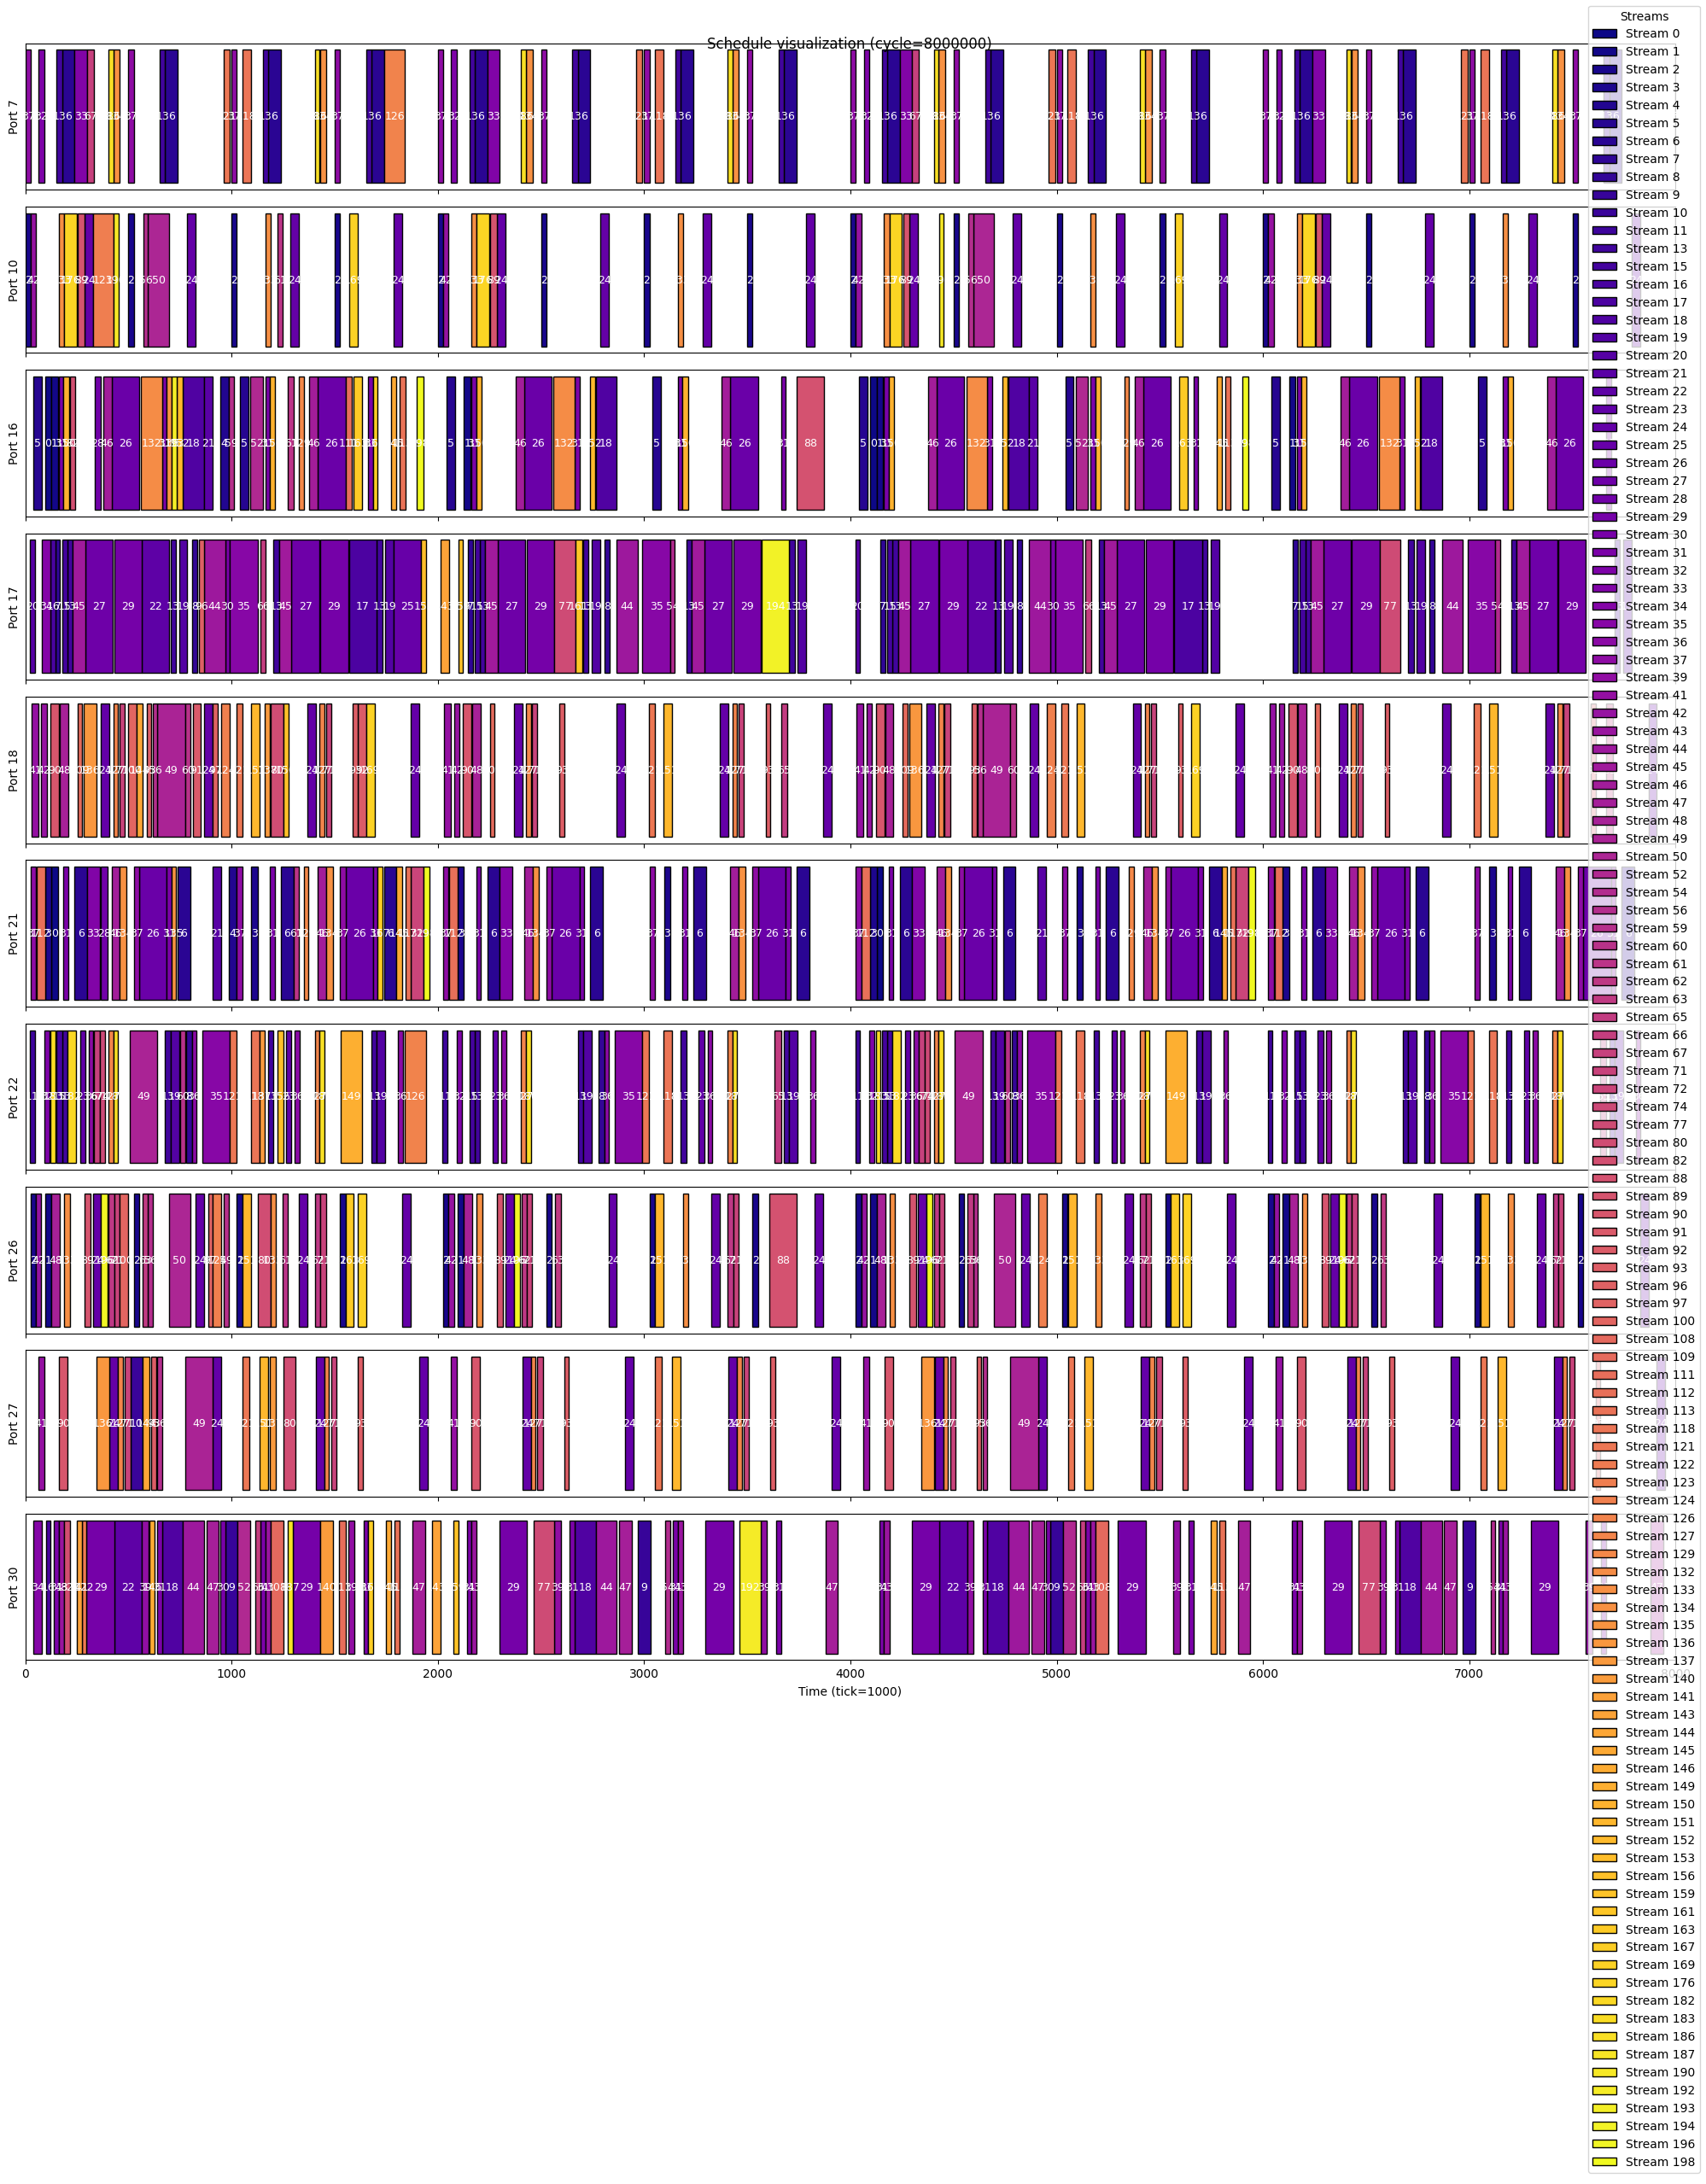

In [34]:
# Pick busiest ports for readable plotting
counts = Counter([slot.port_id for slot in result.schedule])
top_ports = [pid for pid, _ in counts.most_common(10)]
print("Top ports:", top_ports)

fig, axs = result.schedule.plot(
    tick=1000,            # 1000 ns = 1 us on x-axis
    label=True,
    port_ids=top_ports,
)


AttributeError: 'Schedule' object has no attribute 'compile'

In [28]:
import csv
import importlib
import json
from pathlib import Path

import networkx as nx

import schedule as schedule_mod
import ilp_to_platform as i2p
from tsn_scheduling_problem import TSNScheduling
from usecase_generator import Usecase

# Reload modules so notebook uses latest code from schedule.py
importlib.reload(schedule_mod)
importlib.reload(i2p)

# Rebuild conversion result in this cell to avoid stale in-memory objects
artifacts_local = i2p.load_ilp_artifacts(RUN_DIR)
result_local = i2p.convert_ilp_artifacts_to_schedule(
    artifacts_local,
    time_scale_to_ns=time_scale_to_ns,
    duration_mode="robust",
    compact_periodic=False,
)

# Build a Usecase that matches the ILP run topology/streams (do NOT use problem.instantiate()).
graphml_path = RUN_DIR / "network_topology_used.graphml"
if not graphml_path.exists():
    graphml_path = RUN_DIR / "network.graphml"
if not graphml_path.exists():
    raise FileNotFoundError(f"No graphml found in {RUN_DIR}")

streams_csv = RUN_DIR / "streams.csv"
if not streams_csv.exists():
    raise FileNotFoundError(f"No streams.csv found in {RUN_DIR}")

G = nx.read_graphml(graphml_path)

# Build stable per-node port names from neighbors
node_ports = {}
neighbor_order = {}
for node in G.nodes():
    node = str(node)
    neighbors = sorted(str(n) for n in G.neighbors(node))
    neighbor_order[node] = neighbors
    ports = {}
    for idx, _ in enumerate(neighbors, start=1):
        pname = f"Port{idx}"
        ports[pname] = {"name": pname, "speed": 1000, "queueCount": 8}
    node_ports[node] = ports

def node_type(name: str) -> str:
    if "-ED" in name or "-WED" in name:
        return "host"
    return "switch"

# Build usecase JSON schema
nodes = []
for n in sorted(str(x) for x in G.nodes()):
    n_type = node_type(n)
    entry = {"type": n_type, "name": n, "ports": node_ports[n]}
    if n_type == "switch":
        entry["procDelay"] = 0
    nodes.append(entry)

# One directed link per direction so sourcePort exists for each (src, dst) tuple
links = []
for a, b, attrs in G.edges(data=True):
    a = str(a)
    b = str(b)
    a_idx = neighbor_order[a].index(b) + 1
    b_idx = neighbor_order[b].index(a) + 1
    a_port_name = f"Port{a_idx}"
    b_port_name = f"Port{b_idx}"

    prop_delay = int(float(attrs.get("propDelay", 0)))
    link_bw = int(float(attrs.get("linkBw", attrs.get("bandwidth", 1000))))

    links.append(
        {
            "sourceNode": a,
            "destNode": b,
            "sourcePort": f"{a}.{a_port_name}",
            "destPort": f"{b}.{b_port_name}",
            "propDelay": prop_delay,
            "linkBw": link_bw,
        }
    )
    links.append(
        {
            "sourceNode": b,
            "destNode": a,
            "sourcePort": f"{b}.{b_port_name}",
            "destPort": f"{a}.{a_port_name}",
            "propDelay": prop_delay,
            "linkBw": link_bw,
        }
    )

streams = []
with open(streams_csv, newline="") as f:
    reader = csv.DictReader(f)
    for row in reader:
        sid = int(row.get("index", len(streams)))
        src = str(row["src"])

        dst = str(row["dst"])

        period_ns = int(float(row["period"]) * 1000)
        max_latency_ns = int(float(row.get("max_latency", row["period"])) * 1000)
        max_jitter_ns = int(float(row.get("max_jitter", 0)) * 1000)
        packet_size = int(float(row.get("packet_size", 64)))

        streams.append(
            {
                "name": f"stream-{sid}",
                "type": "isochronous",
                "interval": period_ns,
                "maxFramesPerInterval": 1,
                "maxFrameSize": packet_size,
                "maxLatency": max_latency_ns,
                "tlkrPssblPlcmnt": [src],
                "lstnsrPssblPlcmnt": [[dst]],
                "earliest-transmit-offset": 0,
                "latest-transmit-offset": max(0, period_ns // 2),
                "jitter": max_jitter_ns,
            }
        )

imp_uc = {"nodes": nodes, "links": links, "streams": streams, "index": 0}
instance = Usecase.from_json(imp_uc)
problem = TSNScheduling("uc_config.cfg")

# Map ILP tuple ports -> platform sourcePort strings from this matching usecase
edge_to_source_port = {}
for _, _, d in instance.graph.edges(data=True):
    edge_to_source_port[(d["sourceNode"], d["destNode"])] = d["sourcePort"]

port_id_to_name = {0: ""}
for pid, tup in result_local.port_id_to_port_tuple.items():
    if tup not in edge_to_source_port:
        raise KeyError(f"ILP port tuple {tup} not found in imported ILP usecase graph edges")
    port_id_to_name[pid] = edge_to_source_port[tup]

# Attach converted schedule and export/import usecase JSON
instance.addSchedule(result_local.schedule, port_id_to_name)
uc_json_path = "ilp_attached_usecase.json"
with open(uc_json_path, "w") as f:
    json.dump(instance.to_json(), f, indent=2)

instance2 = problem.import_scheduling_usecase(uc_json_path)
print("Attached schedule slots:", len(result_local.schedule))
print("Exported:", uc_json_path)
print("Imported streams:", len(instance2.streams))

Attached schedule slots: 1553
Exported: ilp_attached_usecase.json
Imported streams: 200


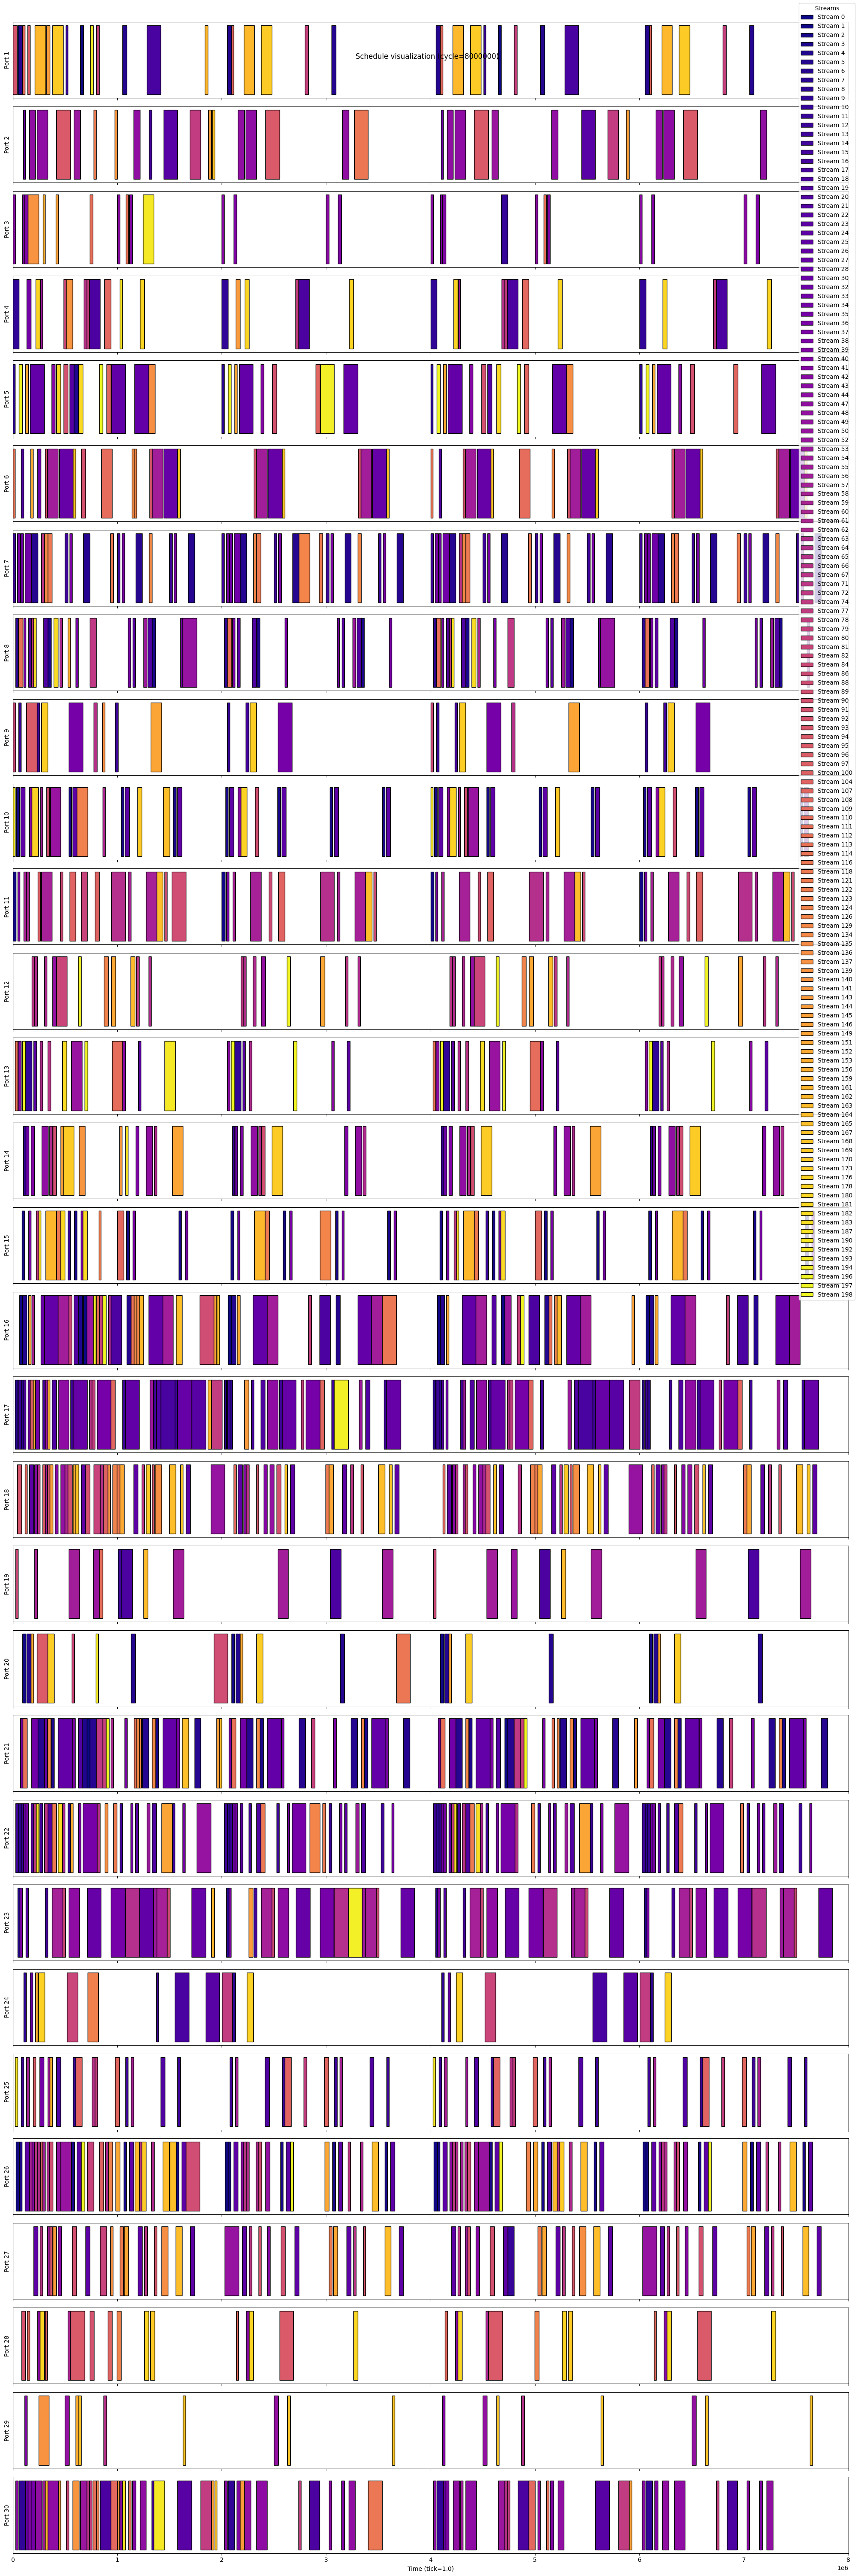

(<Figure size 2000x6000 with 30 Axes>,
 array([<Axes: ylabel='Port 1'>, <Axes: ylabel='Port 2'>,
        <Axes: ylabel='Port 3'>, <Axes: ylabel='Port 4'>,
        <Axes: ylabel='Port 5'>, <Axes: ylabel='Port 6'>,
        <Axes: ylabel='Port 7'>, <Axes: ylabel='Port 8'>,
        <Axes: ylabel='Port 9'>, <Axes: ylabel='Port 10'>,
        <Axes: ylabel='Port 11'>, <Axes: ylabel='Port 12'>,
        <Axes: ylabel='Port 13'>, <Axes: ylabel='Port 14'>,
        <Axes: ylabel='Port 15'>, <Axes: ylabel='Port 16'>,
        <Axes: ylabel='Port 17'>, <Axes: ylabel='Port 18'>,
        <Axes: ylabel='Port 19'>, <Axes: ylabel='Port 20'>,
        <Axes: ylabel='Port 21'>, <Axes: ylabel='Port 22'>,
        <Axes: ylabel='Port 23'>, <Axes: ylabel='Port 24'>,
        <Axes: ylabel='Port 25'>, <Axes: ylabel='Port 26'>,
        <Axes: ylabel='Port 27'>, <Axes: ylabel='Port 28'>,
        <Axes: ylabel='Port 29'>,
        <Axes: xlabel='Time (tick=1.0)', ylabel='Port 30'>], dtype=object))

In [30]:
instance.schedule.plot()

In [12]:
from tsn_scheduling_problem import TSNScheduling
from schedule import Schedule

problem = TSNScheduling("uc_config.cfg")  
uc = problem.import_scheduling_usecase("instance1.json") 
schedddd = Schedule.from_uc_to_sched(uc)

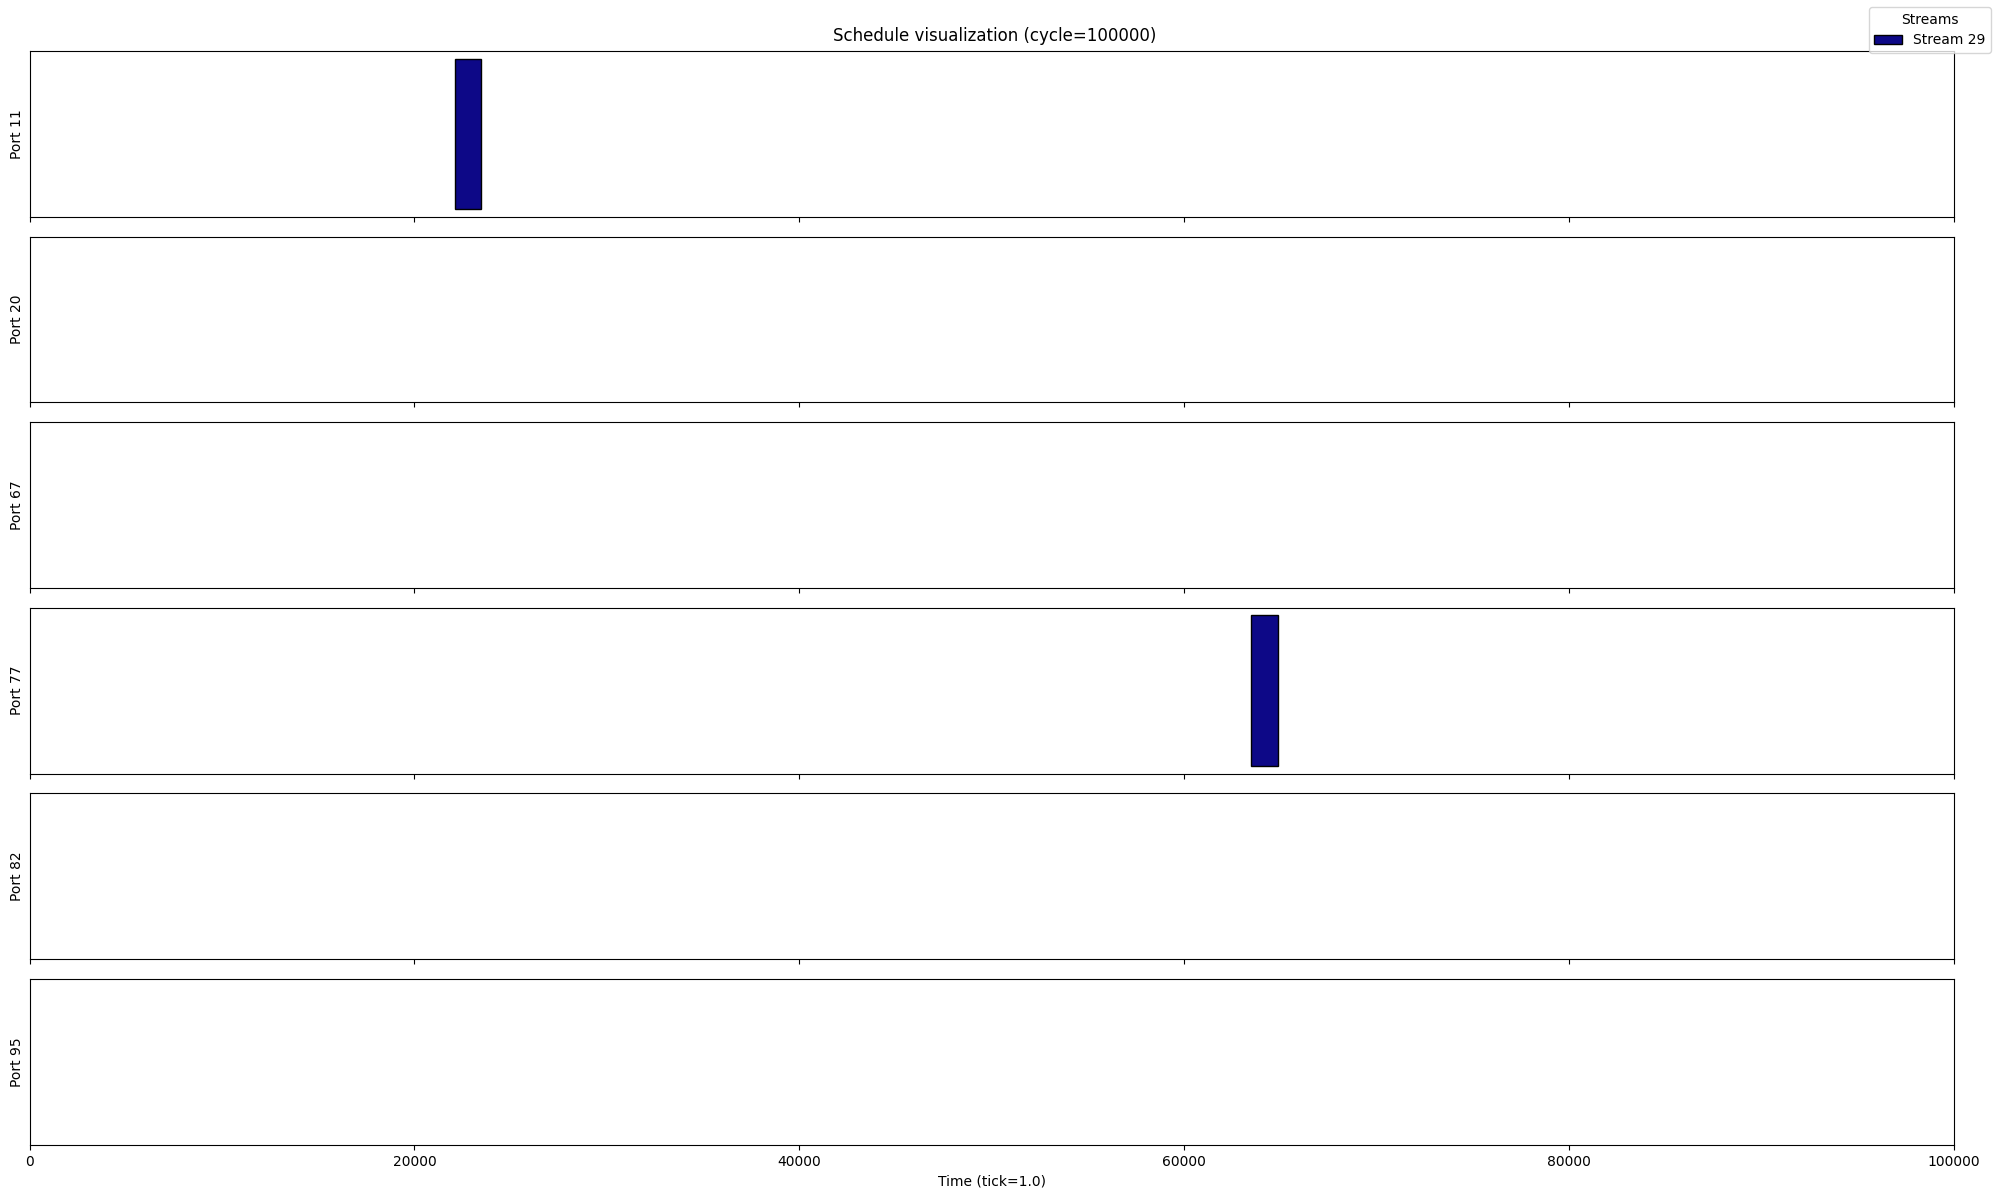

(<Figure size 2000x1200 with 6 Axes>,
 array([<Axes: ylabel='Port 11'>, <Axes: ylabel='Port 20'>,
        <Axes: ylabel='Port 67'>, <Axes: ylabel='Port 77'>,
        <Axes: ylabel='Port 82'>,
        <Axes: xlabel='Time (tick=1.0)', ylabel='Port 95'>], dtype=object))

In [34]:
schedddd.plot(stream_ids=[29],span=None)

In [48]:
import importlib
import schedule as schedule_mod
importlib.reload(schedule_mod)
from schedule import Schedule
from tsn_scheduling_problem import TSNScheduling
from usecase_generator import Usecase

problem = TSNScheduling("uc_config.cfg")
uc = problem.import_scheduling_usecase("instance1.json")

# Use mapping provided by Usecase
port_name_to_id, _ = uc.port_name_id_mapping
schedddd = Schedule.from_usecase(uc, port_name_to_id)

fig1, _ = schedddd.plot(span=None)


AttributeError: 'Usecase' object has no attribute 'port_name_id_mapping'

In [2]:
import importlib
import schedule as schedule_mod
import usecase_generator as uc_mod

importlib.reload(schedule_mod)
importlib.reload(uc_mod)

from schedule import Schedule
from tsn_scheduling_problem import TSNScheduling

problem = TSNScheduling("uc_config.cfg")
uc = problem.import_scheduling_usecase("instance1.json")

# Preferred path: Usecase property access (no parentheses)
if hasattr(uc, "port_name_id_mapping"):
    port_name_to_id, _ = uc.port_name_id_mapping
else:
    # Fallback for stale/mismatched Usecase class objects in notebook kernels
    port_name_to_id = {port_name: idx + 1 for idx, port_name in enumerate(uc.ports)}

schedddd = Schedule.from_usecase(uc, port_name_to_id)
fig1, _ = schedddd.plot(span=None)

NameError: name 'self' is not defined